# Lab: who pays for generative AI? Demand measurement with public data

**BADM 534 · Module 8 (Current Topics), with hooks into M2, M4, M6 and M7** · companion files: `collect_genai_signals.py`, `simulate_subscription_panel.py`, `README.md`

Egan, Russel, Shi and Yao, *Competition in Generative AI: Evidence from Consumer Demand* (NBER Working Paper 35953, October 2026) observe card transactions for 174 million US consumers and ask who pays for ChatGPT-style subscriptions, which plan they buy, how many services they hold, how long they stay, and how price-sensitive they are. Headline facts from the abstract: about **2.9%** of US consumers paid for at least one major service by April 2026; adoption is higher for younger and higher-income consumers; nearly everyone is on a **basic plan of $30 or less**; **multihoming** is common but falling; **annual retention is 20-45%**; **switching rises around model releases**; and the demand model says consumers are **price-sensitive and loyal to AI, not to a provider**.

You cannot get that data. This lab shows what you *can* get, what each public signal does and does not measure, and then works through the paper's measurements on a simulated panel whose data-generating process you can read.

## Plan
- **Part A. Public signals** (adoption, attention, prices, releases), each one HTTP request: Apple App Store charts, Wikipedia pageviews, OpenRouter's model list, the Wayback Machine.
- **Part B. The paper's descriptives on a synthetic panel**: adoption by age and income, plan tiers, multihoming, cohort retention, switching around releases.
- **Part C. A one-line demand model**: recover the price coefficient from aggregate shares and promotional price variation, and say what it implies for pricing power.
- **Exercises**, including the AI-audit exercise that runs through the whole course.

> The live calls in Part A fall back to captures saved in `data/` (taken 26-27 October 2026) when the network blocks them, as it does on some campus networks and on the machine this notebook was executed on. Re-run at home for fresh numbers.

In [1]:
import sys, json, pathlib, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests

LAB = pathlib.Path("collect_genai_signals.py").resolve().parent
DATA = LAB / "data"
sys.path.insert(0, str(LAB))
import collect_genai_signals as sig

pd.set_option("display.width", 140)
def latest(pattern):
    # most recent saved capture matching data/<pattern>
    files = sorted(DATA.glob(pattern))
    return files[-1] if files else None
print("pandas", pd.__version__)

pandas 3.0.5


## Part A. Public signals

### A1. Adoption: App Store top charts

Apple publishes its charts as JSON (`https://rss.marketingtools.apple.com/api/v2/us/apps/top-free/100/apps.json`): no key, no terms beyond ordinary use. Rank is not downloads, and the feed is a snapshot, but the AI assistants sit near the top of the US free chart, and a daily capture over a term turns rank into a time series (see the McBroken lab for the GitHub Actions pattern). The lab's `AI_APPS` table maps App Store ids to providers; the ids were read off the live feed, not typed from memory.

In [2]:
try:
    apple = sig.apple_top_chart("us", "top-free", 100)
    print("live feed, updated", apple.feed_updated.iloc[0])
except Exception as e:
    f = latest("apple_top_free_us_*.csv")
    apple = pd.read_csv(f)
    apple["ai_assistant"] = apple.app_id.isin(sig.AI_APPS)
    apple["provider"] = apple.app_id.map(lambda i: sig.AI_APPS.get(i, (None, None))[1])
    print(f"live call failed ({type(e).__name__}); using saved capture {f.name}")
apple[apple.ai_assistant][["rank", "name", "developer", "provider", "release_date"]]

live call failed (ProxyError); using saved capture apple_top_free_us_2026-10-27.csv


,rank,name,developer,provider,release_date
4,5,ChatGPT,"OpenAI OpCo, LLC",OpenAI,2023-05-18
7,8,Claude by Anthropic,Anthropic PBC,Anthropic,2024-05-01
12,13,Google Gemini,Google,Google,2024-11-13
42,43,Grok AI,X Corp.,xAI,2025-01-08
74,75,Grok Bot,X Corp.,xAI,2026-08-11
79,80,Microsoft Copilot,Microsoft Corporation,Microsoft,2013-06-14


### A2. Attention: Wikipedia pageviews

The Wikimedia REST API returns daily views per article since 2015 (`/metrics/pageviews/per-article/en.wikipedia/all-access/user/<title>/daily/<start>/<end>`). It measures curiosity, not payment, but it is long, daily and free, and it spikes exactly when the paper says switching does: at model launches.

One trap worth seeing with your own eyes. In 2026 the article *Claude (language model)* was renamed *Claude (AI)* and *Gemini (chatbot)* became *Google Gemini*. Pageviews are counted per title, so the old title's series collapses and the new one starts from zero. `wikipedia_pageviews()` resolves redirects through the MediaWiki API and fetches both titles; the saved capture has both so you can see the break.

live call failed (ProxyError); using saved capture


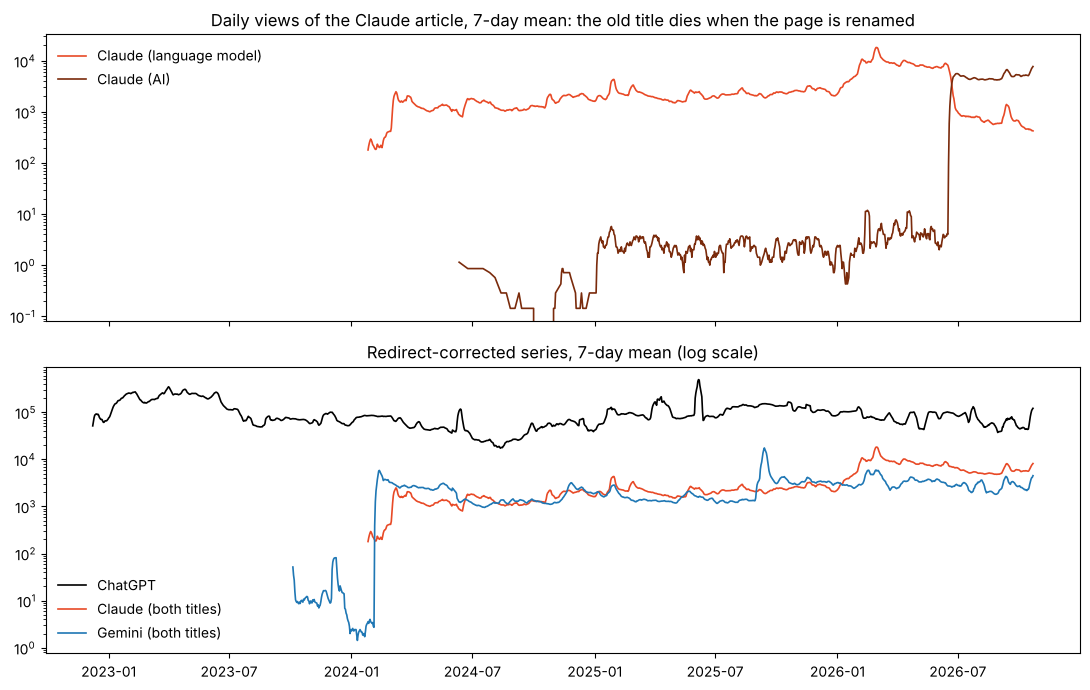

In [3]:
try:
    wiki = sig.wikipedia_pageviews(start="2022-11-01")
    print("live")
except Exception as e:
    wiki = pd.read_csv(latest("wikipedia_pageviews_daily_*.csv"), parse_dates=["date"])
    print(f"live call failed ({type(e).__name__}); using saved capture")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for title, color in [("Claude_(language_model)", "#E84A27"), ("Claude_(AI)", "#7a2b0c")]:
    s = wiki[wiki.article == title].set_index("date").views.rolling(7, center=True).mean()
    axes[0].plot(s.index, s, lw=1.2, color=color, label=title.replace("_", " "))
axes[0].set_title("Daily views of the Claude article, 7-day mean: the old title dies when the page is renamed")
axes[0].legend(frameon=False); axes[0].set_yscale("log")
anth = wiki[wiki.article.isin(["Claude_(language_model)", "Claude_(AI)"])].groupby("date").views.sum()
gg = wiki[wiki.article.isin(["Gemini_(chatbot)", "Google_Gemini"])].groupby("date").views.sum()
cg = wiki[wiki.article == "ChatGPT"].groupby("date").views.sum()
for s, lab, c in [(cg, "ChatGPT", "black"), (anth, "Claude (both titles)", "#E84A27"), (gg, "Gemini (both titles)", "#1f77b4")]:
    axes[1].plot(s.index, s.rolling(7, center=True).mean(), lw=1.2, color=c, label=lab)
axes[1].set_yscale("log"); axes[1].legend(frameon=False)
axes[1].set_title("Redirect-corrected series, 7-day mean (log scale)")
plt.tight_layout()

### A3. Prices on the API side: OpenRouter

Consumer subscription prices are a few numbers on a few web pages (Part A4). The *API* side of the market has hundreds of posted prices, and OpenRouter lists them all at `https://openrouter.ai/api/v1/models` without a key. Prices come as USD per token; the collector converts to USD per million tokens. The `created` field (when a model was listed) doubles as a dated list of launches, which is what the paper needs for "switching around releases". Fradkin (2025, arXiv:2504.15440) uses OpenRouter usage data for the API-side version of the paper's question.

live call failed (ProxyError); using saved capture: 464 models
94 dated model listings; latest:


,created,provider,model_id,usd_per_m_input,usd_per_m_output
89,2026-10-06,google,google/gemini-nano-banana-2.1,1.5,7.5
90,2026-10-07,anthropic,anthropic/claude-haiku-5.5,0.1,0.5
91,2026-10-13,google,google/gemini-4-argon,2.0,10.0
92,2026-10-26,openai,openai/gpt-6.1-terra,1.0,5.0
93,2026-10-26,openai,openai/gpt-6.1-terra-pro,1.0,5.0


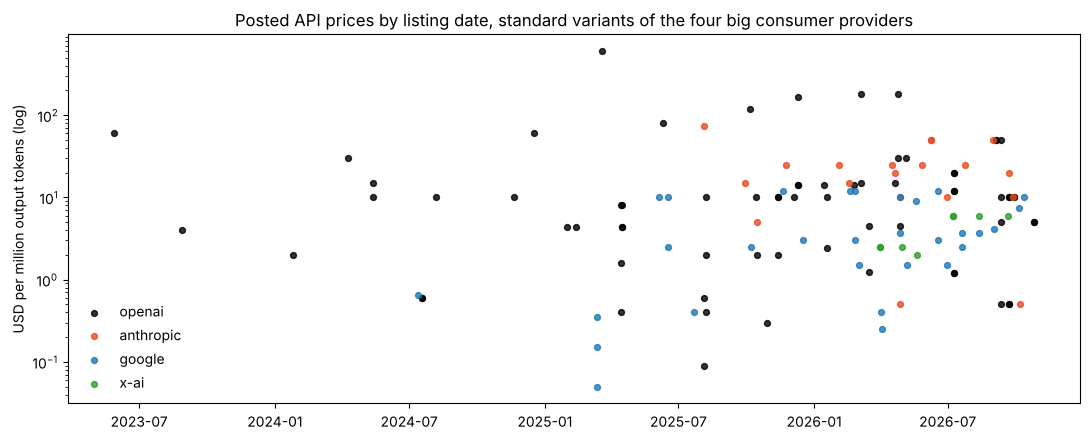

In [4]:
try:
    models = sig.openrouter_models()
    print("live:", len(models), "models")
except Exception as e:
    models = pd.read_csv(latest("openrouter_models_*.csv"), parse_dates=["created"])
    print(f"live call failed ({type(e).__name__}); using saved capture:", len(models), "models")
models["created"] = pd.to_datetime(models["created"])
big = models[models.provider.isin(["openai", "anthropic", "google", "x-ai"]) & (models.variant == "standard") & models.usd_per_m_output.notna()]
fig, ax = plt.subplots(figsize=(11, 4.5))
for prov, c in [("openai", "black"), ("anthropic", "#E84A27"), ("google", "#1f77b4"), ("x-ai", "#2ca02c")]:
    b = big[big.provider == prov]
    ax.scatter(b.created, b.usd_per_m_output, s=18, color=c, alpha=0.8, label=prov)
ax.set_yscale("log"); ax.set_ylabel("USD per million output tokens (log)"); ax.legend(frameon=False)
ax.set_title("Posted API prices by listing date, standard variants of the four big consumer providers")
plt.tight_layout()
events = sig.release_events_from_openrouter(models)
print(f"{len(events)} dated model listings; latest:")
events.tail(5)

### A4. Consumer prices and their history: the Wayback Machine

The paper's price variation comes from plan tiers (basic vs. premium) and changes over time. Providers' pricing pages render the amounts in the browser, so a plain GET often returns the plan names without the numbers; `data/consumer_plans_2026-10-26.csv` records what could be verified on 26 October 2026 and leaves the rest blank on purpose. The Wayback Machine's CDX API lists every archived capture of a page (`http://web.archive.org/cdx/search/cdx?url=claude.com/pricing&output=json&from=2024&collapse=timestamp:8`), and `wayback_fetch_text()` returns the archived page's text, so the price history is an afternoon's work. That is Exercise 1.

In [5]:
plans = pd.read_csv(DATA / "consumer_plans_2026-10-26.csv")
display(plans[["provider", "plan", "tier", "monthly_usd", "annual_usd_per_month", "note"]])
try:
    caps = sig.wayback_snapshots("https://claude.com/pricing", start="2025-01-01")
    print(len(caps), "archived captures of claude.com/pricing since 2025; first:", caps.captured.min())
except Exception as e:
    print(f"Wayback not reachable from this network ({type(e).__name__}); run at home.")

,provider,plan,tier,monthly_usd,annual_usd_per_month,note
0,Anthropic,Claude Free,free,0.00,NaN,NaN
1,Anthropic,Claude Pro,basic,20.00,17.00,annual billed $200 up front
2,Anthropic,Claude Max,premium,100.00,NaN,"from $100; 5x or 20x Pro usage, billed monthly..."
3,Google,Google AI Plus,basic,NaN,NaN,amount rendered client-side; read it from the ...
4,Google,Google AI Pro,basic,19.99,16.67,annual $199.99
5,Google,Google AI Ultra,premium,NaN,NaN,page shows a $99.99/mo Ultra bundle in its sav...
6,OpenAI,ChatGPT Free,free,0.00,NaN,NaN
7,OpenAI,ChatGPT Go,basic,NaN,NaN,amount rendered client-side; may include ads
8,OpenAI,ChatGPT Plus,basic,NaN,NaN,amount rendered client-side
9,OpenAI,ChatGPT Pro,premium,NaN,NaN,'From' price; three usage tiers


Wayback not reachable from this network (ProxyError); run at home.


## Part B. The paper's measurements on a synthetic panel

`simulate_subscription_panel.py` generates 60,000 consumers over January 2023 to April 2026 with a documented data-generating process (open the file: affinity by age and income, provider quality that jumps at releases, inertia, a satiation cost of holding a second subscription that rises over time, promotional discounts). It is **calibrated to the abstract's moments, not estimated from anything**; its purpose is to let you build the paper's tables and figures and see which modelling choices produce which patterns.

In [6]:
subs = pd.read_csv(DATA / "synthetic_subscriptions.csv.gz")
cons = pd.read_csv(DATA / "synthetic_consumers.csv")
prods = pd.read_csv(DATA / "synthetic_products.csv")
rel = pd.read_csv(DATA / "synthetic_releases.csv")
dgp = json.loads((DATA / "synthetic_dgp.json").read_text())
N = dgp["n_consumers"]
months = sorted(subs.month.unique())
print(f"{len(subs):,} consumer-month-product rows, {N:,} consumers, {months[0]} to {months[-1]}")
subs.head()

34,186 consumer-month-product rows, 60,000 consumers, 2023-02 to 2026-04


,consumer_id,month,provider,plan,tier,price,promo,new
0,554,2023-02,OpenAI,ChatGPT Plus,basic,20.0,False,True
1,874,2023-02,OpenAI,ChatGPT Plus,basic,20.0,False,True
2,1390,2023-02,OpenAI,ChatGPT Plus,basic,20.0,False,True
3,1482,2023-02,OpenAI,ChatGPT Plus,basic,20.0,False,True
4,1591,2023-02,OpenAI,ChatGPT Plus,basic,20.0,False,True


### B1. Adoption over time and by demographics

,adoption_by_age,adoption_by_income
age_group,,
18-29,0.0649,NaN
30-44,0.0385,NaN
45-64,0.0137,NaN
65+,0.0042,NaN
high,NaN,0.0552
low,NaN,0.0092
middle,NaN,0.0227


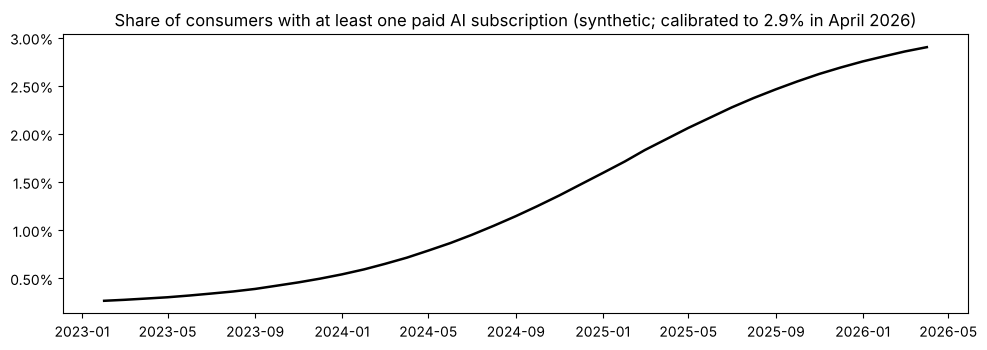

In [7]:
payers = subs.groupby("month").consumer_id.nunique()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(pd.PeriodIndex(payers.index, freq="M").to_timestamp(), payers / N, color="black", lw=1.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of consumers with at least one paid AI subscription (synthetic; calibrated to 2.9% in April 2026)")
plt.tight_layout()

last = subs[subs.month == months[-1]].merge(cons, on="consumer_id")
by_age = last.groupby("age_group").consumer_id.nunique() / cons.age_group.value_counts()
by_inc = last.groupby("income_group").consumer_id.nunique() / cons.income_group.value_counts()
pd.DataFrame({"adoption_by_age": by_age.round(4)}).join(pd.DataFrame({"adoption_by_income": by_inc.round(4)}), how="outer")

### B2. Plan tiers and multihoming

The paper: nearly all paying users choose plans at $30 or less; multihoming is common but has declined as capabilities grew. In the simulation the decline comes from one parameter, the satiation cost of a second subscription, which rises over time. Ask yourself what would produce it in the real world (closer substitutes, bundling, budget fatigue) and how you would tell those apart.

last month: 97.6% of subscriptions are basic plans; 4.1% of payers multihome


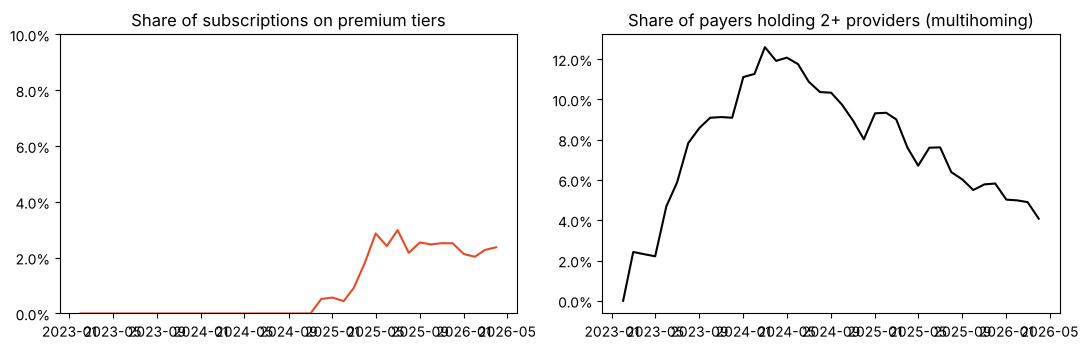

In [8]:
tiers = subs.groupby(["month", "tier"]).size().unstack(fill_value=0)
tiers = tiers.div(tiers.sum(axis=1), axis=0)
multi = (subs.groupby(["month", "consumer_id"]).provider.nunique() > 1).groupby("month").mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
t = pd.PeriodIndex(tiers.index, freq="M").to_timestamp()
axes[0].plot(t, tiers.get("premium", 0), color="#E84A27"); axes[0].set_title("Share of subscriptions on premium tiers"); axes[0].set_ylim(0, 0.1)
axes[1].plot(pd.PeriodIndex(multi.index, freq="M").to_timestamp(), multi, color="black"); axes[1].set_title("Share of payers holding 2+ providers (multihoming)")
for ax in axes: ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
print(f"last month: {tiers.loc[months[-1]].get('basic', 0):.1%} of subscriptions are basic plans; {multi.iloc[-1]:.1%} of payers multihome")

### B3. Retention: provider versus "AI"

Annual retention in the paper is 20-45% per provider. The question that matters for competition is whether a lost customer left AI or just left *you*. Cohort retention curves answer it: for the January 2025 cohort of each provider, what share still pays that provider k months later, and what share still pays *anyone*?

{'OpenAI': np.float64(0.377), 'Anthropic': np.float64(0.328), 'Google': np.float64(0.185)} | any provider: 0.548


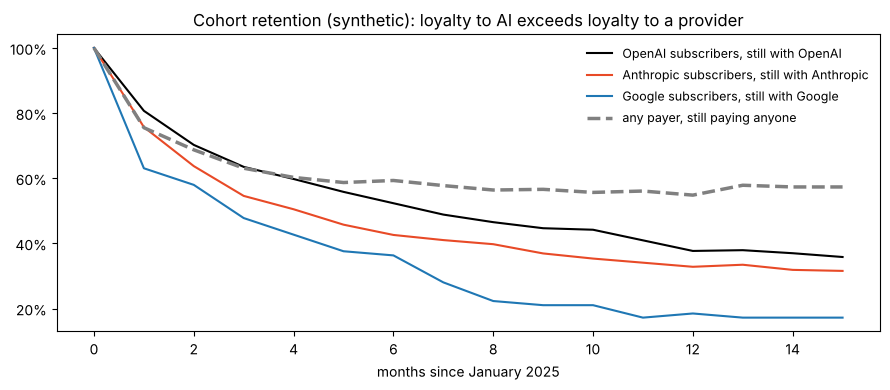

In [9]:
def retention_curve(df, cohort_month, horizon=15):
    start = set(df[df.month == cohort_month].consumer_id)
    out = []
    for k in range(horizon + 1):
        m = (pd.Period(cohort_month, "M") + k).strftime("%Y-%m")
        if m not in months: break
        out.append(len(start & set(df[df.month == m].consumer_id)) / len(start))
    return pd.Series(out)

cohort = "2025-01"
fig, ax = plt.subplots(figsize=(9, 4))
for prov, c in [("OpenAI", "black"), ("Anthropic", "#E84A27"), ("Google", "#1f77b4")]:
    r = retention_curve(subs[subs.provider == prov], cohort)
    ax.plot(r.index, r, color=c, lw=1.5, label=f"{prov} subscribers, still with {prov}")
r_any = retention_curve(subs, cohort)
ax.plot(r_any.index, r_any, color="grey", lw=2.5, ls="--", label="any payer, still paying anyone")
ax.set_xlabel("months since January 2025"); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False, fontsize=9); ax.set_title("Cohort retention (synthetic): loyalty to AI exceeds loyalty to a provider")
plt.tight_layout()
print({p: round(retention_curve(subs[subs.provider == p], cohort).iloc[12], 3) for p in ["OpenAI", "Anthropic", "Google"]}, "| any provider:", round(r_any.iloc[12], 3))

### B4. Switching around model releases

An event-time plot: for each provider's release month (from `synthetic_releases.csv`), the share of that provider's subscribers who are *new* that month, relative to the provider's average in non-release months. In the simulation a release is a quality jump; in the Wikipedia data of Part A2 you saw the attention spike that goes with it.

k
-3    0.023
-2   -0.036
-1   -0.023
 0    0.054
 1   -0.014
 2   -0.049
 3   -0.045
Name: excess, dtype: float64

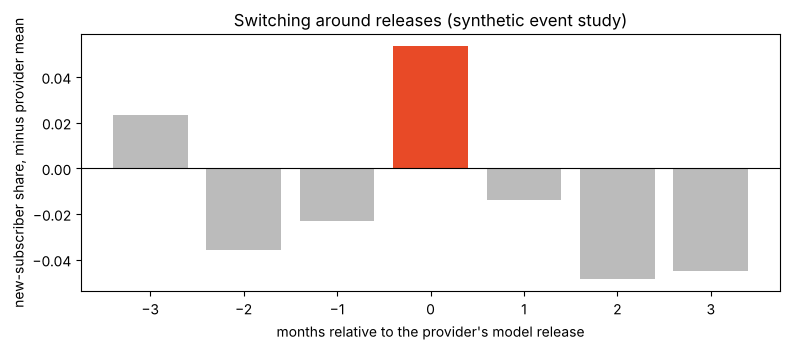

In [10]:
new_rate = subs.groupby(["month", "provider"]).new.mean().reset_index()
rel["month"] = rel["month"].astype(str)
rows = []
for _, e in rel.iterrows():
    for k in range(-3, 4):
        m = (pd.Period(e.month, "M") + k).strftime("%Y-%m")
        v = new_rate[(new_rate.month == m) & (new_rate.provider == e.provider)].new
        if len(v): rows.append({"k": k, "provider": e.provider, "new_rate": float(v.iloc[0]), "size": e["size"]})
ev = pd.DataFrame(rows)
base = new_rate.merge(rel[["provider", "month"]].assign(is_rel=1), on=["provider", "month"], how="left")
base = base[base.is_rel.isna()].groupby("provider").new.mean()
ev["excess"] = ev.new_rate - ev.provider.map(base)
prof = ev.groupby("k").excess.mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(prof.index, prof, color=["#bbbbbb" if k != 0 else "#E84A27" for k in prof.index])
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("months relative to the provider's model release")
ax.set_ylabel("new-subscriber share, minus provider mean"); ax.set_title("Switching around releases (synthetic event study)")
plt.tight_layout()
prof.round(3)

## Part C. A one-line demand model

The paper estimates a structural model of demand and supply. Here is the smallest version that still teaches the mechanics. Let $s_{jt}$ be the share of consumers holding provider $j$'s basic plan in month $t$ and $p_{jt}$ its price. With binary-logit demand per product,

$$\ln\frac{s_{jt}}{1-s_{jt}} = \delta_j + \tau_t - \alpha\, p_{jt} + \xi_{jt},$$

so $\alpha$ is identified by price changes within a product, after product and month effects. In the simulation the only within-product price changes are promotional discounts (as in life: free months, student deals, holiday offers). The DGP's true value is in `synthetic_dgp.json`; the regression below is plain OLS with dummies, so you can see every step.

In [11]:
prices = pd.read_csv(DATA / "synthetic_basic_prices.csv")
basic = subs[subs.tier == "basic"]
share = (basic.groupby(["month", "provider"]).consumer_id.nunique() / N).rename("s").reset_index()          # stock: who holds it
flow = (basic[basic.new].groupby(["month", "provider"]).consumer_id.nunique() / N).rename("f").reset_index()  # flow: who just took it
d = share.merge(prices, on=["month", "provider"]).merge(flow, on=["month", "provider"], how="left").fillna({"f": 0.0})

def fe_logit(df, y):
    # OLS of log-odds on product dummies, month dummies and price: the "Berry inversion" in its simplest form
    X = pd.concat([pd.get_dummies(df.provider), pd.get_dummies(df.month, drop_first=True), df[["basic_price"]]], axis=1).astype(float)
    beta, *_ = np.linalg.lstsq(X.values, y, rcond=None)
    resid = y - X.values @ beta
    se = np.sqrt((resid @ resid / (len(df) - X.shape[1])) * np.linalg.inv(X.values.T @ X.values)[-1, -1])
    return -beta[-1], se

a_stock, se_stock = fe_logit(d, np.log(d.s / (1 - d.s)))
dd = d[d.f > 0]
a_flow, se_flow = fe_logit(dd, np.log(dd.f / (1 - dd.f)))
print(f"true alpha in the DGP                      = {dgp['alpha_price']:.3f}")
print(f"alpha from the STOCK of subscribers         = {a_stock:.3f}  (s.e. {se_stock:.3f})")
print(f"alpha from the FLOW of new subscribers      = {a_flow:.3f}  (s.e. {se_flow:.3f})")
print(f"{d.promo.mean():.0%} of product-months carry a promotional price; those are the identifying observations")
p0 = 20.0
print(f"flow-based elasticity at ${p0:.0f}: {-a_flow * p0 * (1 - dd.f.mean()):.2f}; a $1 rise cuts new sign-ups by about {a_flow * (1 - dd.f.mean()):.1%}")

true alpha in the DGP                      = 0.060
alpha from the STOCK of subscribers         = 0.030  (s.e. 0.015)
alpha from the FLOW of new subscribers      = 0.050  (s.e. 0.011)
16% of product-months carry a promotional price; those are the identifying observations
flow-based elasticity at $20: -1.00; a $1 rise cuts new sign-ups by about 5.0%


**Why the two estimates differ.** The stock of subscribers moves slowly because most of them are inert (the DGP has an inertia term; the paper has retention of 20-45% a year), so a three-month promotion barely dents the share of holders and the static regression understates price sensitivity. The flow of new sign-ups responds to the price on offer and gets close to the true value. The paper's structural model handles this by modelling the subscribe/renew decision itself; the lesson for you is that "demand" for a subscription is a dynamic object.

**What this does and does not say.** The elasticity above is for one product with everyone else held fixed; the paper's claim about pricing power needs the *cross* elasticities (how much of a lost ChatGPT subscriber goes to Claude rather than to nothing), which is why they estimate a model with a nest for "paid AI" and provider-level loyalty. Compare the provider retention curves with the any-provider curve in B3: that gap is the nest. A nested-logit extension is Exercise 4.

## Exercises

1. **Price history (M2).** Use `sig.wayback_snapshots()` and `sig.wayback_fetch_text()` to list the archived captures of `https://claude.com/pricing` and `https://chatgpt.com/pricing` since 2023, extract the dollar amounts with a regular expression, and build a `provider, plan, month, price` table. Fill the blanks in `data/consumer_plans_2026-10-26.csv`. Which launch dates in `simulate_subscription_panel.py` are wrong?
2. **Rank into a panel (M2).** Put `collect_genai_signals.py --apple` into a daily GitHub Actions job (copy `snapshot_mcbroken.yml` from the McBroken lab). After a month, plot each assistant's rank and relate the moves to the release list from A3.
3. **Attention and releases (M6).** Using the Wikipedia series and the OpenRouter release list, estimate the average pageview response in the 7 days after a provider's release relative to the 7 days before. Does ChatGPT's response look different in 2023 and 2026? Say what the comparison does and does not identify.
4. **Nested logit (M7/M8).** Add an inclusive-value term so that the model distinguishes "leave AI" from "switch provider". The simulation's satiation parameter `kappa` rises over time; what pattern should that leave in the nesting parameter?
5. **Audit the AI.** Ask your assistant to write `wikipedia_pageviews()` from scratch given only the API URL. Compare with the lab's version: does it set a User-Agent (Wikimedia throttles anonymous clients), handle the 404 for titles with no views, follow redirects, and note that zero-view days are missing? Keep the diff for your write-up.
6. **Ramp AI Index (M8).** Ramp publishes monthly paid-AI adoption among US businesses from its own card data, by vendor. Compare its vendor shares with the Apple ranks and the Wikipedia attention shares. Which of the three is closest to what the paper measures, and why?